# Análisis del clima en Pasto en 2016-2025

## Introducción

Este análisis describe cómo varían la temperatura media y la precipitación mensual en Pasto durante el periodo 2016–2025. La pregunta que orienta el trabajo es: **¿cómo cambiaron estas variables entre los meses y entre los años analizados?**

Los datos se obtuvieron mediante `api_data_collector`, que consulta la [API histórica de Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api), basada en datos de reanálisis ERA5. Se solicitaron datos para las coordenadas 1.214578, -77.278117; la API reportó 1.25, -77.25. El periodo analizado va del 1 de enero de 2016 al 31 de diciembre de 2025.

El análisis utiliza registros diarios de temperatura media y precipitación acumulada. A partir de ellos, se comparan los promedios mensuales de temperatura y los acumulados mensuales de precipitación entre años; también se calcula un promedio mensual para el periodo completo.

### Carga y Validación de los datos

Se cargan tres archivos generados por `api_data_collector`:

- `pasto_daily_weather.csv`: registros diarios de temperatura y precipitación.
- `pasto_monthly_weather_summary.csv`: resumen de las variables por año y mes.
- `pasto_monthly_climatology_2016_2025.csv`: promedios mensuales calculados para el periodo 2016–2025.

Se revisan las dimensiones, el rango de fechas, las fechas duplicadas y los valores faltantes de los registros diarios.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


current_path = Path.cwd().resolve()
possible_roots = [current_path, *current_path.parents]

PROJECT_ROOT = next(
    (path for path in possible_roots if (path / "pyproject.toml").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"No se encontró pyproject.toml desde: {current_path}. "
        "Abre en VS Code la carpeta api_data_collector y vuelve a ejecutar la celda."
    )

DATA_DIR = PROJECT_ROOT / "data"

daily_path = DATA_DIR / "pasto_daily_weather.csv"
monthly_path = DATA_DIR / "pasto_monthly_weather_summary.csv"
climatology_path = DATA_DIR / "pasto_monthly_climatology_2016_2025.csv"

for file_path in (daily_path, monthly_path, climatology_path):
    if not file_path.is_file():
        raise FileNotFoundError(f"No se encontró el archivo: {file_path}")

daily = pd.read_csv(daily_path)
monthly = pd.read_csv(monthly_path)
climatology = pd.read_csv(climatology_path)

daily["date"] = pd.to_datetime(daily["date"])

print(f"Registros diarios: {daily.shape[0]}")
print(f"Resúmenes año-mes: {monthly.shape[0]}")
print(f"Meses en climatología: {climatology.shape[0]}")
print(f"Rango de fechas: {daily['date'].min()} a {daily['date'].max()}")
print(f"Fechas duplicadas: {daily['date'].duplicated().sum()}")

datasets = {
    "datos diarios": daily,
    "resumen mensual": monthly,
    "climatología mensual": climatology,
}

for dataset_name, dataframe in datasets.items():
    missing_by_column = dataframe.isna().sum()

    print(f"\nValores faltantes en {dataset_name}:")
    display(missing_by_column.rename("valores_faltantes").to_frame())

    total_missing = int(missing_by_column.sum())
    if total_missing == 0:
        print("No se encontraron valores faltantes.")
    else:
        print(f"Total de valores faltantes: {total_missing}")

print("\nClimatología mensual:")
display(climatology)

Registros diarios: 3653
Resúmenes año-mes: 120
Meses en climatología: 12
Rango de fechas: 2016-01-01 00:00:00 a 2025-12-31 00:00:00
Fechas duplicadas: 0

Valores faltantes en datos diarios:


,valores_faltantes
date,0
temperature_2m_mean_c,0
precipitation_sum_mm,0


No se encontraron valores faltantes.

Valores faltantes en resumen mensual:


,valores_faltantes
year,0
month,0
temperature_mean_c,0
precipitation_sum_mm,0
temperature_days,0
precipitation_days,0


No se encontraron valores faltantes.

Valores faltantes en climatología mensual:


,valores_faltantes
month,0
temperature_climatology_mean_c,0
precipitation_climatology_mean_mm,0
temperature_years,0
precipitation_years,0


No se encontraron valores faltantes.

Climatología mensual:


,month,temperature_climatology_mean_c,precipitation_climatology_mean_mm,temperature_years,precipitation_years
0,1,15.17,178.41,10,10
1,2,15.47,206.15,10,10
2,3,15.28,299.63,10,10
3,4,15.41,261.54,10,10
4,5,15.47,217.77,10,10
5,6,14.98,159.14,10,10
6,7,14.74,103.32,10,10
7,8,14.98,80.49,10,10
8,9,15.40,102.92,10,10
9,10,15.25,201.55,10,10


En los csv producidos por api_data_collector se logró identificar que con las coordenadas que ubican a la ciudad de Pasto Nariño en Colombia los registros existentes en el periodo 2016 - 2025 son de 3653, el resumen de cada año con sus meses es de 120 registros, los meses en climatologia son 12, no se evidencian valores faltantes o nulos.

### Climatología mensual promedio del periodo 2016-2025

Gráfico de líneas con marcadores para mostrar como cambia el promedio mensual de temperatura a lo largo del año y gráfico de barras, para comparar el total mensual promedio entre meses.

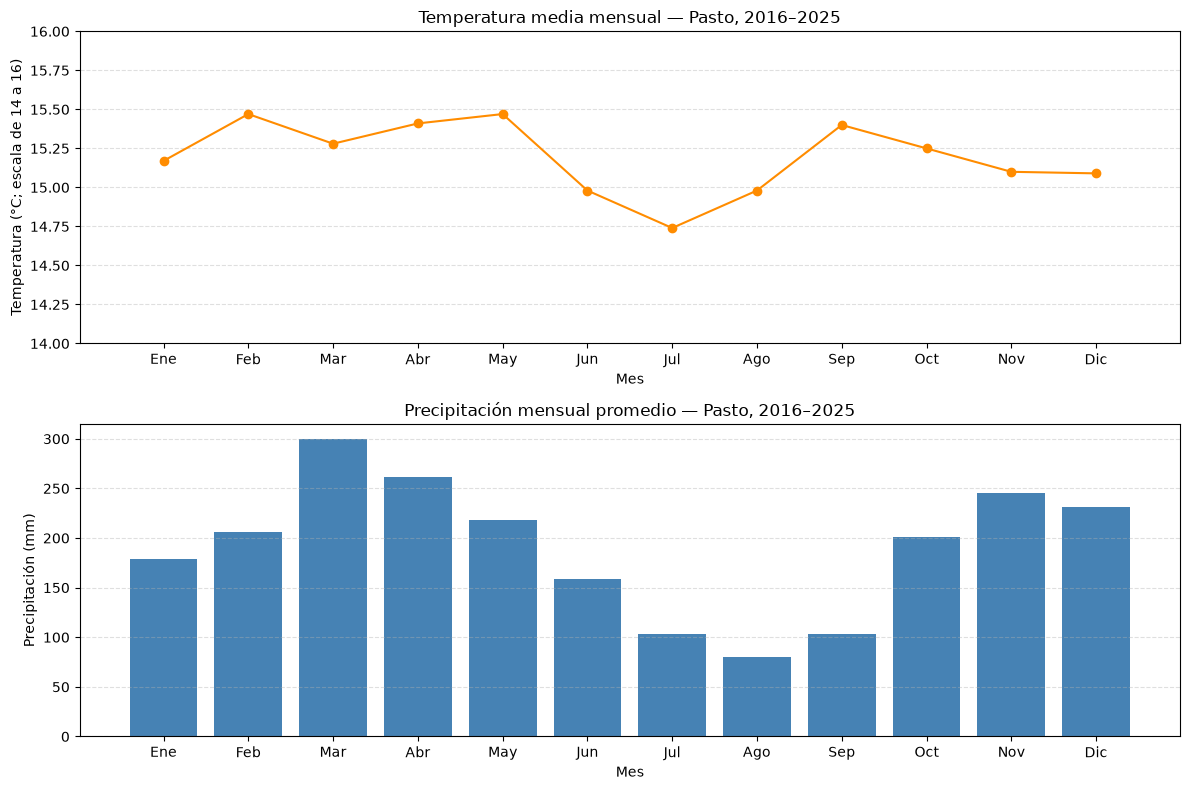

In [2]:
month_names = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]

climatology_plot = climatology.sort_values("month")

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
)

axes[0].plot(
    climatology_plot["month"],
    climatology_plot["temperature_climatology_mean_c"],
    marker="o",
    color="darkorange",
)
axes[0].set_title("Temperatura media mensual — Pasto, 2016–2025")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

axes[1].bar(
    climatology_plot["month"],
    climatology_plot["precipitation_climatology_mean_mm"],
    color="steelblue",
)
axes[1].set_title("Precipitación mensual promedio — Pasto, 2016–2025")
axes[1].set_ylabel("Precipitación (mm)")
axes[1].set_xlabel("Mes")
axes[1].set_xticks(climatology_plot["month"])
axes[1].set_xticklabels(month_names)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].set_ylim(14, 16)
axes[0].set_ylabel("Temperatura (°C; escala de 14 a 16)")
axes[0].set_xlabel("Mes")
axes[0].tick_params(axis="x", labelbottom=True)

plt.tight_layout()
plt.show()

#### Hallazgos 

**Temperatura**

Durante 2016–2025, los promedios mensuales de temperatura más altos se registraron en febrero y mayo, ambos con aproximadamente 15,47 °C. El promedio más bajo se presentó en julio, con 14,74 °C. La diferencia entre estos promedios es de 0,73 °C.

**Precipitación**

El promedio de los acumulados mensuales de precipitación fue mayor en marzo, con 299,63 mm, y menor en agosto, con 80,49 mm. La diferencia entre ambos promedios es de 219,14 mm. En los datos, el promedio aumenta gradualmente desde agosto hasta noviembre, cuando alcanza 245,13 mm; en diciembre baja a 231,00 mm.

### Variación por año y mes 

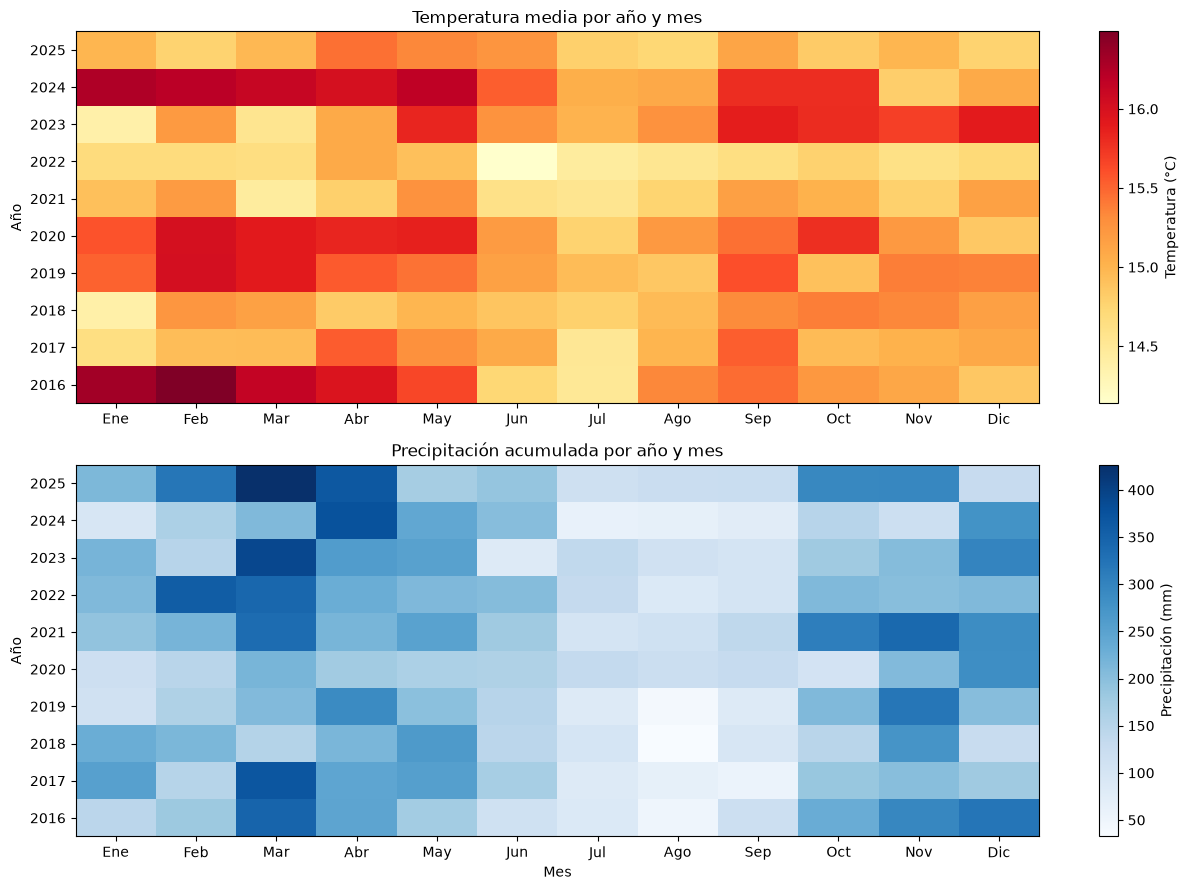

In [3]:
temperature_matrix = monthly.pivot(
    index="year",
    columns="month",
    values="temperature_mean_c",
)

precipitation_matrix = monthly.pivot(
    index="year",
    columns="month",
    values="precipitation_sum_mm",
)

month_names = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(13, 9),
)

temperature_image = axes[0].imshow(
    temperature_matrix,
    aspect="auto",
    origin="lower",
    cmap="YlOrRd",
)
axes[0].set_title("Temperatura media por año y mes")
axes[0].set_ylabel("Año")
axes[0].set_yticks(range(len(temperature_matrix.index)))
axes[0].set_yticklabels(temperature_matrix.index)
axes[0].set_xticks(range(12))
axes[0].set_xticklabels(month_names)
fig.colorbar(temperature_image, ax=axes[0], label="Temperatura (°C)")

precipitation_image = axes[1].imshow(
    precipitation_matrix,
    aspect="auto",
    origin="lower",
    cmap="Blues",
)
axes[1].set_title("Precipitación acumulada por año y mes")
axes[1].set_ylabel("Año")
axes[1].set_xlabel("Mes")
axes[1].set_yticks(range(len(precipitation_matrix.index)))
axes[1].set_yticklabels(precipitation_matrix.index)
axes[1].set_xticks(range(12))
axes[1].set_xticklabels(month_names)
fig.colorbar(precipitation_image, ax=axes[1], label="Precipitación (mm)")

plt.tight_layout()
plt.show()

#### Hallazgos

**Temperatura**

El mapa de calor permite comparar la temperatura media de cada mes entre años. Entre enero y abril de 2016 y 2024 se observan valores similares, aproximadamente entre 16,0 °C y 16,5 °C. En 2023, las temperaturas de septiembre a diciembre estuvieron por encima de los promedios climatológicos de esos meses. Estas diferencias muestran variación entre años, pero el mapa por sí solo no permite determinar sus causas.

**Precipitación**

El mapa muestra cómo cambió el acumulado mensual de precipitación entre años. En marzo de 2017 se registraron 368,7 mm; en marzo de 2023, 390,1 mm; y en marzo de 2025, 426,8 mm. Los tres valores superan el promedio climatológico de marzo, que fue de 299,63 mm. Esto permite destacar esos años, aunque no significa que marzo haya sido el mes más lluvioso en todos los años.

### Limitaciones 

Los datos corresponden a la celda ERA5 reportada por Open-Meteo para las coordenadas solicitadas de Pasto. Representan estimaciones de reanálisis, no mediciones directas de una estación meteorológica. El periodo de diez años permite describir estos datos, pero no constituye una normal climática oficial de treinta años ni permite atribuir causas a los patrones observados.

### Conclusión

En conjunto, los promedios de 2016–2025 muestran una variación mensual relativamente pequeña en la temperatura y diferencias más marcadas en la precipitación. Los mapas de calor añaden el detalle de cómo varían estas condiciones entre años: algunos meses se apartan del promedio del periodo. Por tanto, los promedios climatológicos resumen el patrón mensual general, mientras que los mapas permiten observar las diferencias de cada año.
